# How Severe Weather and Public Events Disrupt MBTA Green Line B Travel Times

**Team:** BA780-A08  
**Contributors:** Susan Huang, Ingrid Felix, Ruining Shan, Tia Theseira and Kaiser Lu

## Executive Summary
**Objective:** The analysis aims to inform MBTA officials and Boston-area commuters about how adverse weather, public events, and seasonal volume impact the travel times and reliability of the Green Line B Branch.   

**Data & Method:**  The findings are based on a merged dataset comparing September and December 2025, which includes 539,798 MBTA travel records, NOAA hourly weather logs, and City of Boston special event permits.   

**Key Findings:** Above-ground segments are the main cause of schedule unpredictability, showing nearly triple the variance of underground segments (192.9s vs. 66.7s standard deviation) even on normal days.   While peak hours add approximately 1.5 minutes to the median end-to-end travel time, they result in a tighter standard deviation (5.6 minutes) compared to off-peak hours (6.6 minutes).   Baseline travel is significantly slower during the September back-to-school rush (771.5s median per segment) compared to December (696.8s).



## Table of Contents
1. Introduction & Motivation
2. Project Proposal & Data Sources
3. Data Cleaning & Pre-processing
4. Team Assignment Recap (Initial EDA)
5. Baseline Analysis: How does the line perform on a normal day?
6. Weather: Does precipitation increase travel time?
7. Events: Do public events increase travel time?
8. Rider impact: Do weather and events together increase delay and reduce reliability?
9. Conclusion & Recommendations
10. Challenges
11. References
12. Generative AI Disclosure

## 1. Introduction & Motivation

Picture a rainy December morning at Boston University Central. The platform is crowded, the next B train is “arriving” for the third time, and there is no way to know whether the trip downtown will take 40 minutes or an hour. For BU students like us, , the Green Line B Branch runs right through our campus, and it is how many students and commuters get to class and work.

The B Branch is unique because it runs both above ground and below ground. From **Boston College to Kenmore**, the train travels **above ground**, and the rest of the line is below ground. We want to see how factors such as **bad weather and public events** affect the line's travel time and reliability.

We wanted to know how much these disruptions impact the riders. Does rain or snow make average trip time more significantly longer? Do public events slow the line down, and when? What happens if there is bad weather and a huge public event?

This is important because riders need to consider how much extra time to plan for when commuting, the MBTA needs to understand when service may be affected, and event organizers in Boston need to understand how their events may impact public transportation.

To find out, we compared two very different months: **September**, with the start of the semester and fall events, and **December**, with colder weather and holiday crowds. We start by setting a baseline for how the line performs, then measure how weather, events, and how the two factors combined change travel time and reliability. We would like to provide get better insights to understand disruptions on the Green Line B Branch.

## 2. Project Proposal & Data Sources
**Problem statement:** The Green Line B Branch runs largely above ground along Commonwealth Avenue, and bad weather and public events can impact the train times, but it is not clear by how much. We measure how precipitation, temperature and public events change travel time and reliability on the B Branch, and which parts of the line are hit hardest.

**Scope:** Green Line B branch; weather and public events in September and December.

**Data sources:**
| Dataset | Source / link | Time range | Key fields | License |
|---|---|---|---|---|
| MBTA Rapid Transit Travel Times 2025 | [MBTA Open Data Portal](https://mbta-massdot.opendata.arcgis.com/datasets/5f71a5c035fc4a4dad1b7fa73ba27ef8/about) | September and December 2025 | date, route_id, direction,<br>from_stop_name, to_stop_name, travel time | MassDOT Developers<br>License Agreement |
| Local Climatological Data (LCD) v2 | [NOAA National Centers for Environmental Information](https://www.ncei.noaa.gov/access/search/datasets/local-climatological-data-v2/?endDate=2025-12-31T23:59:59&p=1&startDate=2025-01-01T00:00:00&esriMagicKey=dHA9MCN0dj02MDc5N2RiNyNsb2M9MTA5NjkzNzUjbG5nPTQxI3BsPTkxNzQ2MTUjZmE9NjU1MzYjbGJzPTE0OjE1MjI4ODMyI2xuPVdvcmxk) | January to December 2025 | HourlyPrecipitation, HourlyDryBulbTemperature,<br>HourlyWindSpeed, DailySnowDepth | U.S. Government Work<br>(public domain) |
| Special Event License Applications | [Analyze Boston (City of Boston)](https://data.boston.gov/dataset/special-event-license-applications/resource/fb05bfda-a57e-4d97-948b-4f1949ba3c8a) | Events starting in 2025 | App Name, Status, Start Date and Time,<br>End Date and Time, Zip Code | Open Data Commons Public<br>Domain Dedication and License (PDDL) |

In [135]:
# Imports and settings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# 3. Data Cleaning & Pre-processing


## 3.1 Load data

In [108]:
path_sep = "gs://teama08/ba780-team-data/MBTAGreenline/2025-09_LRTravelTimes.csv"
path_dec = "gs://teama08/ba780-team-data/MBTAGreenline/2025-12_LRTravelTimes.csv"
weather_path = "gs://teama08/ba780-team-data/BostonWeather/LCD_USW00014739_2025.csv"
event_path = "gs://teama08/ba780-team-data/BostonEvent/fb05bfda-a57e-4d97-948b-4f1949ba3c8a (1).csv"

b_sep_df = pd.read_csv(path_sep)
b_dec_df = pd.read_csv(path_dec)
weather_df = pd.read_csv(weather_path)
event_df = pd.read_csv(event_path)

# Keep only the Green Line B branch because the MBTA files include every Green Line branch: B, C, D and E
b_sep_df = b_sep_df[b_sep_df['route_id'] == 'Green-B'].copy()
b_dec_df = b_dec_df[b_dec_df['route_id'] == 'Green-B'].copy()

# Check each table to show only 'Green-B'
print(b_sep_df['route_id'].value_counts())
print(b_dec_df['route_id'].value_counts())

/tmp/ipykernel_285/2209492938.py:6: DtypeWarning: Columns (2,6,9) have mixed types. Specify dtype option on import or set low_memory=False.
  b_sep_df = pd.read_csv(path_sep)
/tmp/ipykernel_285/2209492938.py:7: DtypeWarning: Columns (2,6,9) have mixed types. Specify dtype option on import or set low_memory=False.
  b_dec_df = pd.read_csv(path_dec)
/tmp/ipykernel_285/2209492938.py:8: DtypeWarning: Columns (19,60,108,111,113) have mixed types. Specify dtype option on import or set low_memory=False.
  weather_df = pd.read_csv(weather_path)


route_id
Green-B    1774241
Name: count, dtype: int64
route_id
Green-B    1117499
Name: count, dtype: int64


## 3.2 Clean & standardize
*Missing values, data types, timestamps/time zones, duplicates, outliers.*

In [109]:
# Check how many missing values are there in the B-Line Sep Dataset.
b_sep_df.isna().sum()

,0
service_date,0
route_id,0
trip_id,0
direction_id,0
direction,0
from_parent_station,0
from_stop_id,0
from_stop_name,0
to_parent_station,0
to_stop_id,0


In [110]:
# Check how many missing values are there in the B-Line Dec Dataset.
b_dec_df.isna().sum()

,0
service_date,0
route_id,0
trip_id,0
direction_id,0
direction,0
from_parent_station,0
from_stop_id,0
from_stop_name,0
to_parent_station,0
to_stop_id,0


In [111]:
# Extract Time Features
b_sep_df['departure_time'] = pd.to_datetime(b_sep_df['from_stop_departure_datetime'])
b_sep_df['date'] = b_sep_df['departure_time'].dt.date
b_sep_df['hour'] = b_sep_df['departure_time'].dt.hour

b_dec_df['departure_time'] = pd.to_datetime(b_dec_df['from_stop_departure_datetime'])
b_dec_df['date'] = b_dec_df['departure_time'].dt.date
b_dec_df['hour'] = b_dec_df['departure_time'].dt.hour

# Group the dataset by date, hour, route, direction
group_cols = ['date', 'hour', 'route_id', 'direction', 'from_stop_name', 'to_stop_name']
b_sep_agg = b_sep_df.groupby(group_cols)['travel_time_sec'].agg(
    avg_travel_time_sec='mean',
    trip_count='count'
).reset_index()

group_cols = ['date', 'hour', 'route_id', 'direction', 'from_stop_name', 'to_stop_name']
b_dec_agg = b_dec_df.groupby(group_cols)['travel_time_sec'].agg(
    avg_travel_time_sec='mean',
    trip_count='count'
).reset_index()
# Format Time Labels into Ordered AM/PM
b_sep_agg['hour_label'] = b_sep_agg['hour'].apply(
    lambda h: f"{12 if h % 12 == 0 else h % 12} {'AM' if h < 12 else 'PM'}"
)
ordered_hours = [f"{12 if h % 12 == 0 else h % 12} {'AM' if h < 12 else 'PM'}" for h in range(24)]
b_sep_agg['hour_label'] = pd.Categorical(b_sep_agg['hour_label'], categories=ordered_hours, ordered=True)

b_dec_agg['hour_label'] = b_dec_agg['hour'].apply(
    lambda h: f"{12 if h % 12 == 0 else h % 12} {'AM' if h < 12 else 'PM'}"
)
ordered_hours = [f"{12 if h % 12 == 0 else h % 12} {'AM' if h < 12 else 'PM'}" for h in range(24)]
b_dec_agg['hour_label'] = pd.Categorical(b_dec_agg['hour_label'], categories=ordered_hours, ordered=True)

b_sep_agg = b_sep_agg.drop(columns=['hour'])
b_dec_agg = b_dec_agg.drop(columns=['hour'])
display(b_sep_agg.head())
display(b_dec_agg.head())

,date,route_id,direction,from_stop_name,to_stop_name,avg_travel_time_sec,trip_count,hour_label
0,2025-09-01,Green-B,East,Allston Street,Amory Street,429.5,2,5 AM
1,2025-09-01,Green-B,East,Allston Street,Arlington,1164.0,2,5 AM
2,2025-09-01,Green-B,East,Allston Street,Babcock Street,336.0,2,5 AM
3,2025-09-01,Green-B,East,Allston Street,Blandford Street,709.5,2,5 AM
4,2025-09-01,Green-B,East,Allston Street,Boston University Central,582.0,2,5 AM


,date,route_id,direction,from_stop_name,to_stop_name,avg_travel_time_sec,trip_count,hour_label
0,2025-12-01,Green-B,East,Allston Street,Amory Street,541.20,5,5 AM
1,2025-12-01,Green-B,East,Allston Street,Arlington,1354.75,4,5 AM
2,2025-12-01,Green-B,East,Allston Street,Babcock Street,415.80,5,5 AM
3,2025-12-01,Green-B,East,Allston Street,Ball Square,2355.00,1,5 AM
4,2025-12-01,Green-B,East,Allston Street,Blandford Street,808.80,5,5 AM


In [112]:
# Check how many missing values are there in the Weather Dataset.
pd.set_option('display.max_rows', None)
weather_df.isna().sum()

,0
STATION,0
DATE,0
LATITUDE,0
LONGITUDE,0
ELEVATION,0
NAME,0
REPORT_TYPE,0
SOURCE,377
HourlyAltimeterSetting,3207
HourlyDewPointTemperature,377


In [113]:
# Create A Copy
weather_df_raw = weather_df.copy()

# Convert DATE to datetime and extract date and hour
weather_df_raw['DATE_parsed'] = pd.to_datetime(weather_df_raw['DATE'], errors='coerce')
weather_df_raw['date'] = weather_df_raw['DATE_parsed'].dt.date
weather_df_raw['hour'] = weather_df_raw['DATE_parsed'].dt.hour

# Select relevant columns
target_columns = [
    'date', 'hour',
    'HourlyPrecipitation',
    'HourlyDryBulbTemperature',
    'HourlyWindSpeed',
    'DailySnowDepth'
]

existing_cols = [col for col in target_columns if col in weather_df_raw.columns]
weather_clean = weather_df_raw[existing_cols].copy()

# Clean messy values and convert to numeric type
for col in existing_cols:
    if col not in ['date', 'hour']:
        if weather_clean[col].dtype == object:
            weather_clean[col] = weather_clean[col].astype(str).str.replace('T', '0.01', regex=False)
            weather_clean[col] = weather_clean[col].str.replace(r'[a-zA-Z*]', '', regex=True)
        weather_clean[col] = pd.to_numeric(weather_clean[col], errors='coerce')

# Standardize text columns
text_cols = weather_clean.select_dtypes(include='object').columns
text_cols = [col for col in text_cols if col not in ['date', 'hour']]

for col in text_cols:
    weather_clean[col] = weather_clean[col].str.strip()

# Fill in DailySnowDepth by day
if 'DailySnowDepth' in weather_clean.columns:
    weather_clean['DailySnowDepth'] = (
      weather_clean.groupby('date')['DailySnowDepth'].transform(lambda x: x.ffill().bfill())
    )

# Fill remaining missing values
for col in existing_cols:
    if col not in ['date', 'hour']:
        weather_clean[col] = weather_clean[col].fillna(0)

# Drop rows where date or hour is null (due to parsing errors, if any)
weather_clean = weather_clean.dropna(subset=['date', 'hour'])

weather_hourly = weather_clean.groupby(['date', 'hour']).mean().reset_index()
weather_hourly['hour_label'] = weather_hourly['hour'].apply(
    lambda h: f"{12 if h % 12 == 0 else int(h % 12)} {'AM' if h < 12 else 'PM'}"
)
weather_hourly = weather_hourly.drop(columns=['hour'])

display(weather_hourly.head())

,date,HourlyPrecipitation,HourlyDryBulbTemperature,HourlyWindSpeed,DailySnowDepth,hour_label
0,2025-01-01,0.000000,3.350000,3.100000,0.0,12 AM
1,2025-01-01,0.400000,6.950000,6.450000,0.0,1 AM
2,2025-01-01,1.500000,7.033333,4.633333,0.0,2 AM
3,2025-01-01,7.100000,6.700000,7.066667,0.0,3 AM
4,2025-01-01,0.103333,7.033333,5.500000,0.0,4 AM


In [114]:
# Check how many missing values are there in the Dataset which we had cleaned.
weather_hourly.isna().sum()

,0
date,0
HourlyPrecipitation,0
HourlyDryBulbTemperature,0
HourlyWindSpeed,0
DailySnowDepth,0
hour_label,0


In [115]:
# Convert start and end dates to datetime
event_df["Start Date and Time"] = pd.to_datetime(
    event_df["Start Date and Time"], errors="coerce"
)
event_df["End Date and Time"] = pd.to_datetime(
    event_df["End Date and Time"], errors="coerce"
)

# Filter for events taking place in 2025
events_2025 = event_df[
    (event_df["Start Date and Time"].dt.year == 2025)
    | (event_df["End Date and Time"].dt.year == 2025)
].copy()
event_clean = events_2025.copy()

# Drop all columns that contain any missing values
event_clean = event_clean.dropna(axis=1)
event_clean.head()


,_id,App Number,App Name,Status,Application Date,Start Date and Time,End Date and Time
220,221,PUB1880038,Gospel Fest,Closed,2026-07-29 20:28:41+00,2025-08-30,2025-08-30
427,428,PUB1856335,Santa Rosalia Annual Procession,Closed,2026-06-01 14:06:53+00,2025-09-13,2025-09-13
906,907,PUB1807162,Wasabi Fenway Bowl Pep Rally,Open,2025-12-18 15:45:26+00,2025-12-26,2025-12-26
913,914,PUB1806425,Amulet Ribbon Cutting,Closed,2025-12-16 07:05:54+00,2025-12-19,2025-12-19
916,917,PUB1806303,Chanukah Celebration,Closed,2025-12-15 18:46:24+00,2025-12-18,2025-12-18


In [116]:
# Check how many missing values are there in the Dataset which we had cleaned for Events.
event_clean.isna().sum()

,0
_id,0
App Number,0
App Name,0
Status,0
Application Date,0
Start Date and Time,0
End Date and Time,0


## 3.3 Merge & feature engineering


In [117]:
import datetime

# from event_clean generate daily_event_counts
event_clean['date'] = pd.to_datetime(event_clean['Start Date and Time']).dt.date
daily_event_counts = event_clean.groupby('date').size().reset_index(name='event_count_daily')

b_sep_agg['date'] = pd.to_datetime(b_sep_agg['date']).dt.date
b_dec_agg['date'] = pd.to_datetime(b_dec_agg['date']).dt.date
weather_hourly['date'] = pd.to_datetime(weather_hourly['date']).dt.date
daily_event_counts['date'] = pd.to_datetime(daily_event_counts['date']).dt.date

merged_sep = pd.merge(b_sep_agg, weather_hourly, on=['date', 'hour_label'], how='left')
merged_dec = pd.merge(b_dec_agg, weather_hourly, on=['date', 'hour_label'], how='left')
combined_transit_weather = pd.concat([merged_sep, merged_dec], ignore_index=True)

combined_transit_weather['date_dt'] = pd.to_datetime(combined_transit_weather['date'])
combined_transit_weather = combined_transit_weather.sort_values(['date_dt', 'hour_label'])

weather_cols = ['HourlyPrecipitation', 'HourlyDryBulbTemperature', 'HourlyWindSpeed', 'DailySnowDepth', 'rain', 'snow']
for col in weather_cols:
    if col in combined_transit_weather.columns:
        combined_transit_weather[col] = combined_transit_weather[col].ffill().bfill()

final_merged_df = pd.merge(combined_transit_weather, daily_event_counts, on='date', how='left')
final_merged_df['event_count_daily'] = final_merged_df['event_count_daily'].fillna(0)

drop_cols = ['month', 'hour', 'date_dt']
final_merged_df.drop(columns=[c for c in drop_cols if c in final_merged_df.columns], inplace=True, errors='ignore')

print(f"Final Dataset Shape: {final_merged_df.shape}")
display(final_merged_df.head())

Final Dataset Shape: (539798, 13)


,date,route_id,direction,from_stop_name,to_stop_name,avg_travel_time_sec,trip_count,hour_label,HourlyPrecipitation,HourlyDryBulbTemperature,HourlyWindSpeed,DailySnowDepth,event_count_daily
0,2025-09-01,Green-B,East,Allston Street,Amory Street,701.20,5,1 PM,0.0,23.3,6.2,0.0,4.0
1,2025-09-01,Green-B,East,Allston Street,Arlington,1585.25,4,1 PM,0.0,23.3,6.2,0.0,4.0
2,2025-09-01,Green-B,East,Allston Street,Babcock Street,545.20,5,1 PM,0.0,23.3,6.2,0.0,4.0
3,2025-09-01,Green-B,East,Allston Street,Blandford Street,1102.80,5,1 PM,0.0,23.3,6.2,0.0,4.0
4,2025-09-01,Green-B,East,Allston Street,Boston University Central,842.60,5,1 PM,0.0,23.3,6.2,0.0,4.0


In [118]:
# Check how many missing values are there in the Merged Dataset.
final_merged_df.isna().sum()

,0
date,0
route_id,0
direction,0
from_stop_name,0
to_stop_name,0
avg_travel_time_sec,0
trip_count,0
hour_label,0
HourlyPrecipitation,0
HourlyDryBulbTemperature,0


# 4. Team Assignment Recap (Initial EDA)
In the Team Assignment phase, our group established the data pipeline and baseline Exploratory Data Analysis (EDA) to evaluate how extreme weather and large public gatherings disrupt point-to-point travel times on the **MBTA Green Line B Branch**.

### 1. Project Scope & Problem Definition
We compared two distinct seasonal profiles in 2025—**September** (heat, rain, and high-volume fall events/university move-in) and **December** (freezing temperatures, snow/ice, and holiday gatherings)—while segmenting the B Branch into **Below-Ground** stops (Government Center to Kenmore) and **Above-Ground** stops (Blandford Street to Boston College).

### 2. Data Cleaning & Merging Pipeline
We ingested, cleaned, and merged three primary datasets from Google Cloud Storage by **date and hour** into a unified analytical dataset of **539,798 rows**:
* **MBTA Light Rail Travel Times (`2025-09` & `2025-12`):** Filtered specifically for `route_id == 'Green-B'`, converting departure/arrival timestamps to standardized datetime formats and calculating point-to-point travel times (`travel_time_sec`).
* **NOAA Local Climatological Data (`LCD_USW00014739_2025.csv`):** Extracted hourly weather observations from Boston Logan Airport, cleaning numeric fields for dry bulb temperature and hourly precipitation (handling trace `'T'` values and mixed data types).
* **City of Boston Special Event Applications (`2025`):** Standardized start and end datetime columns, filtered for active 2025 events, and removed invalid/`VOID`/`TEST` entries to quantify hourly event density across the city.

3. Key Findings from Exploratory Data Analysis (EDA)

Our baseline EDA addressed five core questions across the three datasets to establish our benchmark metrics:

| Domain | Metric / Question | Key Finding / Baseline Result |
| :--- | :--- | :--- |
| **Weather (Temperature)** | Average Monthly Temperature (2025) | Demonstrated a sharp seasonal contrast between **September (~20°C / 68°F)** and **December (~0°C / 32°F)**, validating our two-season comparison framework. |
| **Weather (Precipitation)** | Average Monthly Precipitation (2025) | Identified key precipitation spikes across 2025, isolating rainy days in September vs. wintry precipitation (snow/ice) in December. |
| **MBTA Travel Times** | End-to-End Travel Time (`Boston College` $\leftrightarrow$ `Government Center`) | Quantified baseline end-to-end travel times in both directions (Eastbound vs. Westbound) across September and December, revealing higher travel time variance during peak hours and inclement weather. |
| **MBTA Trip Volume** | Total Completed Trips (`Boston College` $\leftrightarrow$ `Government Center`) | Compared total trip counts between September and December across both directions, establishing baseline service frequency and capacity. |
| **Boston Public Events** | Total Monthly Events (2025) | Mapped the monthly distribution of permitted city events, showing high event concentration in late summer/early fall (**September**) and a secondary seasonal cluster of holiday markets and tree lightings in **December**. |

---
**Transition to Final Analysis:** Building on the **539,798-row** merged dataset created in the Team Assignment, the following sections investigate specific segment bottlenecks (above-ground vs. below-ground), event-driven congestion near key stops (e.g., Kenmore/BU campus), and compound weather-event delays.

# 5. Baseline Analysis: How does the Green Line B Branch perform on a normal day?


In [119]:
# Prepping merged data set

# Copy of the merged data
b_line = final_merged_df.copy()

# Keep only full trips between Boston College and Government Center so every row covers the same distance
end_stops = ['Boston College', 'Government Center']
b_line = b_line[b_line['from_stop_name'].isin(end_stops) & b_line['to_stop_name'].isin(end_stops)].copy()

# Convert travel time from seconds to minutes
b_line['travel_time_min'] = b_line['avg_travel_time_sec'] / 60

# Convert hour labels like '5 PM' into military time using the ordered_hours list
hour_lookup = {label: number for number, label in enumerate(ordered_hours)}
b_line['hour'] = b_line['hour_label'].astype(str).map(hour_lookup)

# Peak hours are 7-9 AM and 16-18 PM in military time
peak_hours = [7, 8, 9, 16, 17, 18]

# Label each row 'Peak' or 'Off-Peak' based on hour column
b_line['period'] = np.where(b_line['hour'].isin(peak_hours), 'Peak', 'Off-Peak')

# Check how many rows we kept in each direction (if 0, check stop spelling with final_merged_df['from_stop_name'].unique())
print('Number of rows:', len(b_line))
print(b_line['direction'].value_counts())

# Preview first 3 rows
b_line[['date', 'hour_label', 'direction', 'from_stop_name', 'to_stop_name', 'travel_time_min', 'period']].head(3)

Number of rows: 1873
direction
West    989
East    884
Name: count, dtype: int64


,date,hour_label,direction,from_stop_name,to_stop_name,travel_time_min,period
57,2025-09-01,1 PM,East,Boston College,Government Center,47.266667,Off-Peak
392,2025-09-01,1 PM,West,Government Center,Boston College,49.011111,Off-Peak
563,2025-09-01,10 AM,East,Boston College,Government Center,43.690000,Off-Peak


##1. Is median travel time higher during peak hours (7–10 AM, 4–7 PM) than during off-peak hours?

  *Hypothesis: We expect median travel time on the Green Line B Branch to be higher during peak hours (7–10 AM, 4–7 PM) than during off peak hours because the increase in ridership and street traffic may delay the times at each stop, causing an increase in median travel time.*

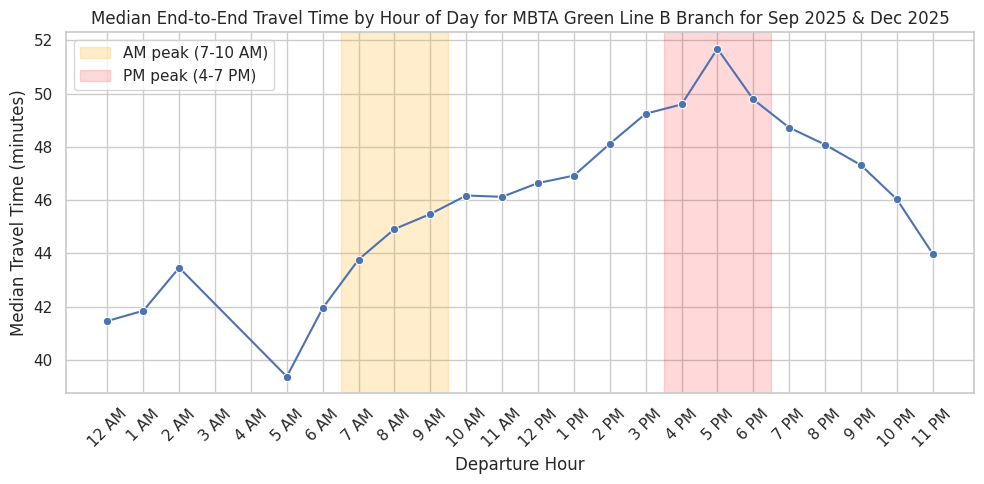

Median travel time (minutes):
period
Off-Peak    46.3
Peak        47.8
Name: travel_time_min, dtype: float64


In [120]:
# Graph 1

# Calculate median travel time for each hour of the day
hourly_median = b_line.groupby('hour')['travel_time_min'].median().reset_index()

# Plot line chart of median travel time by hour
plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_median, x='hour', y='travel_time_min', marker='o')

# Shade the AM and PM peak hours
plt.axvspan(6.5, 9.5, color='orange', alpha=0.2, label='AM peak (7-10 AM)')
plt.axvspan(15.5, 18.5, color='red', alpha=0.15, label='PM peak (4-7 PM)')

# Show AM/PM labels on the x-axis instead of military time hours
plt.xticks(range(24), ordered_hours, rotation=45)

# Add the title, axis labels and legend
plt.title('Median End-to-End Travel Time by Hour of Day for MBTA Green Line B Branch for Sep 2025 & Dec 2025')
plt.xlabel('Departure Hour')
plt.ylabel('Median Travel Time (minutes)')
plt.legend()
plt.tight_layout()
plt.show()

# Print the median travel time for peak vs. off-peak
print('Median travel time (minutes):')
print(b_line.groupby('period')['travel_time_min'].median().round(1))

**Question 1 Conclusion:** Median end-to-end travel time was 47.8 minutes during peak hours and 46.3 minutes during off-peak hours, a difference of 1.5 minutes. B branch is slower during rush hour in the AM and PM. The line chart shows median travel time is highest around 5 PM.

## 2. Is the standard deviation of travel time higher during peak hours than during off-peak hours?

*Hypothesis: We expect the standard deviation of travel time on the Green Line B Branch to be higher during peak hours than during off-peak hours because there is more ridership and street traffic, leading to less predictable timings.*

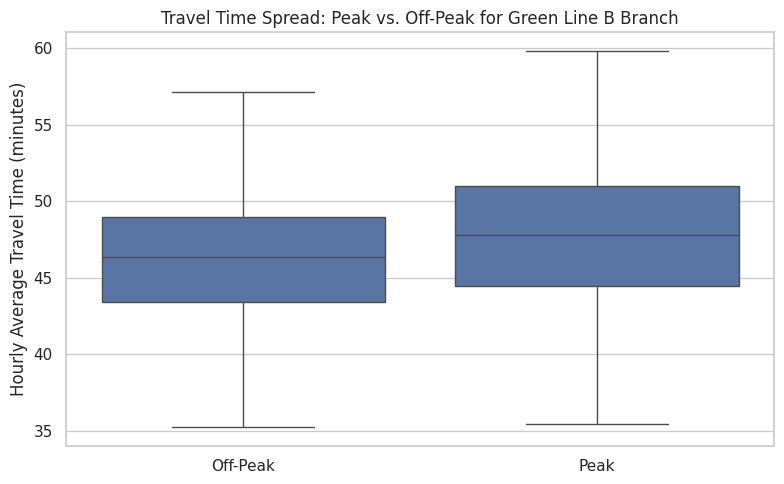

Standard deviation of travel time (minutes):
period
Off-Peak    6.6
Peak        5.6
Name: travel_time_min, dtype: float64


In [121]:
# Graph 2

# Box plot comparing travel times in off-peak and peak hours & removing all outliers
plt.figure(figsize=(8, 5))

# We removed the outliers to make the chart more readable. The standard deviation calculation includes all the data.
sns.boxplot(data=b_line, x='period', y='travel_time_min', order=['Off-Peak', 'Peak'], showfliers=False)

# Add the title and axis labels
plt.title('Travel Time Spread: Peak vs. Off-Peak for Green Line B Branch')
plt.xlabel('')
plt.ylabel('Hourly Average Travel Time (minutes)')
plt.tight_layout()
plt.show()

# Print the standard deviation for peak vs. off-peak to answer the question
print('Standard deviation of travel time (minutes):')
print(b_line.groupby('period')['travel_time_min'].std().round(1))

**Question 2 Conclusion:** Travel times were less spread out during peak hours, with a standard deviation of 5.6 min, compared to an off-peak standard deviation of 6.6 min, so rush hour does make the B branch more predictable.

## 3. Is inbound median travel time higher than outbound during the AM peak, and outbound higher than inbound during the PM peak?

*Hypothesis: We expect inbound (Boston College to Government Center) median travel time to be higher than outbound during the AM peak, and outbound (Government Center to Boston College) median travel time to be higher than inbound during the PM peak. This is because commuters and students mostly travel toward downtown in the morning, and vice versa during the PM peak hours.*

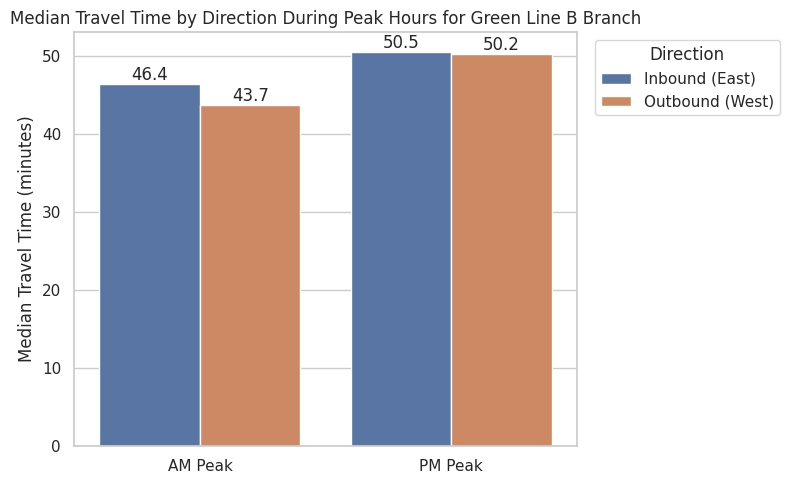

In [122]:
# Graph 3

# Keep only peak hour rows
peak_rows = b_line[b_line['hour'].isin(peak_hours)].copy()

# Label each row 'AM Peak' & 'PM Peak' depending if it is before or after noon
peak_rows['peak'] = np.where(peak_rows['hour'] < 12, 'AM Peak', 'PM Peak')

# Rename direction labels
# East is Boston College to Government Center (inbound)
# West is Government Center to Boston College (outbound)
peak_rows['direction_label'] = peak_rows['direction'].map({'East': 'Inbound (East)', 'West': 'Outbound (West)'})

# Calculate median travel time for each peak period and direction
q3_summary = peak_rows.groupby(['peak', 'direction_label'])['travel_time_min'].median().reset_index()

# Plot grouped bar chart with one bar per direction for each peak period
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=q3_summary, x='peak', y='travel_time_min', hue='direction_label')

# Write the travel time value on top of each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f')

# Add the title, axis labels, and a legend placed outside the bars
plt.title('Median Travel Time by Direction During Peak Hours for Green Line B Branch')
plt.xlabel('')
plt.ylabel('Median Travel Time (minutes)')
plt.legend(title='Direction', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Question 3 Conclusion:** In the AM peak, inbound/East trips from Boston College to Government Center were slower than outbound/West trips from Government Center to Boston College(46.4 vs. 43.7 min). In the PM peak, however, outbound and inbound median travel times were similar (50.5 min inbound vs. 50.2 min outbound). Both directions were also on average 4–6 minutes slower in the PM peak than in the AM peak.

## 4. Is the standard deviation of travel time higher on above-ground segments than on below-ground segments on normal days (no precipitation, no events)?

*Hypothesis: We expect travel time to be more variable on above-ground segments than on below-ground segments, because above-ground trains share the street with cars and stop at traffic lights, while underground trains run separately from traffic.*

Normal days: 9
segment_type
Above-ground    192.941720
Below-ground     66.652336
Name: std_travel_time, dtype: float64


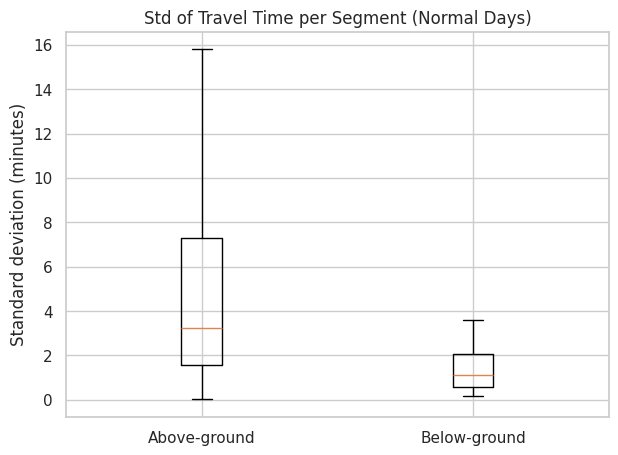

In [123]:
#Graph 4

df = final_merged_df.copy()

# Data cleaning - making sure the dates, months, precipitation and events columns have no empty values and are the correct data type
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.month

# Keep only September and December (removes January 1st, 2026)
df = df[df['month'].isin([9, 12])]

df['HourlyPrecipitation'] = pd.to_numeric(df['HourlyPrecipitation'], errors='coerce').fillna(0)
df['event_count_daily'] = df['event_count_daily'].fillna(0)
daily_precip = df.drop_duplicates(['date', 'hour_label'])

# Sum of precipitation every hour by day
daily_precip = daily_precip.groupby('date')['HourlyPrecipitation'].sum()
df['daily_precip'] = df['date'].map(daily_precip)

# Normal days = no precipitation and no events
normal = df[(df['daily_precip'] == 0) & (df['event_count_daily'] == 0)].copy()
print('Normal days:', normal['date'].nunique())

underground_stops = ['Kenmore', 'Hynes Convention Center', 'Copley', 'Arlington',
'Boylston', 'Park Street', 'Government Center']

# Created a segment type column where if both the to_stop_name and from_stop_name are in the list of underground stops it will be labeled as below ground
normal['segment_type'] = np.where(
    normal['from_stop_name'].isin(underground_stops) & normal['to_stop_name'].isin(underground_stops),
'Below-ground', 'Above-ground')

# Standard deviation of average travel time in seconds for segment, direction and segment type
seg_std = (normal.groupby(['from_stop_name', 'to_stop_name', 'direction', 'segment_type'])
                 ['avg_travel_time_sec'].std()
                 .reset_index(name='std_travel_time'))

print(seg_std.groupby('segment_type')['std_travel_time'].median())

# This breaks in two data frames: above and below
above = seg_std[seg_std['segment_type'] == 'Above-ground']['std_travel_time'].dropna()
below = seg_std[seg_std['segment_type'] == 'Below-ground']['std_travel_time'].dropna()

# Convert standard deviation from seconds to minutes for the chart
above_min = above / 60
below_min = below / 60

# Chart
plt.figure(figsize=(7, 5))

# We removed the outliers to make the chart more readable. The standard deviation calculation includes all the data.
plt.boxplot([above_min, below_min], tick_labels=['Above-ground', 'Below-ground'], showfliers=False)
plt.title('Std of Travel Time per Segment (Normal Days)')
plt.ylabel('Standard deviation (minutes)')
plt.show()


**Question 4 Conclusion:** The results support our hypothesis. We found only 9 normal days (no rain and no events) in the data. On these days, the travel time changes more on above-ground segments than on below-ground segments (median standard deviation of about 3.2 vs. 1.1 minutes). The box for above-ground segments is also much bigger (from about 1.6 to 7.3 minutes) than the box for below-ground segments (from about 0.6 to 2.1 minutes), so the travel time is less predictable above ground. This can be explained by traffic and traffic lights. Below ground, the travel time is more stable. We removed the outliers from the chart to make the boxes easier to compare, but they are still included in the calculations.

## 5. On days with no precipitation and no events, is median travel time higher in December than in September? Overlaid distributions.

*Hypothesis: We expect median travel time to be higher in September than in December, because September is the start of the fall semester, so the trains are more busy with students going back to school.*

month
9     4
12    2
Name: date, dtype: int64
Records in September: 164
Records in December: 42
Median September (min): 47.8
Median December (min): 43.1


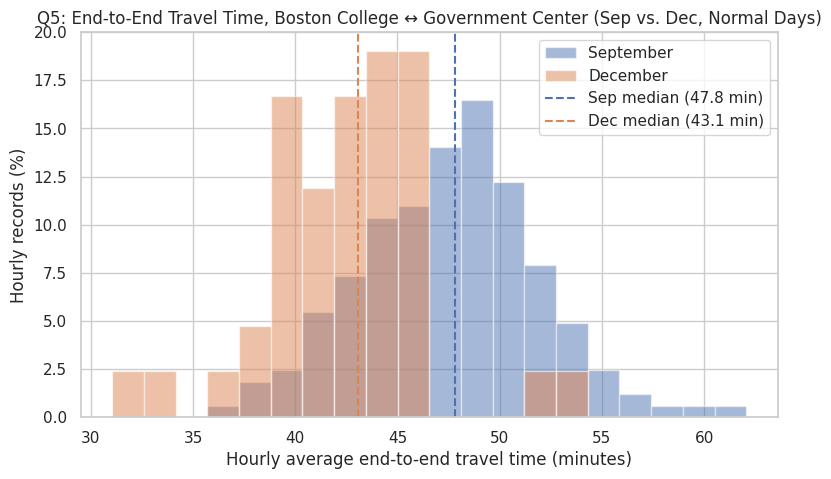

In [124]:
#Graph 5

#keep only full trips between Boston College and Government Center (end to end) on normal days
end_to_end = normal[
    ((normal['from_stop_name'] == 'Boston College') & (normal['to_stop_name'] == 'Government Center')) |
    ((normal['from_stop_name'] == 'Government Center') & (normal['to_stop_name'] == 'Boston College'))
].copy()

#convert travel time from seconds to minutes
end_to_end['travel_time_min'] = end_to_end['avg_travel_time_sec'] / 60

#end-to-end travel times for September and December
sep = end_to_end[end_to_end['month'] == 9]['travel_time_min']
dec = end_to_end[end_to_end['month'] == 12]['travel_time_min']

#how many normal days and records in each month
print(end_to_end.groupby('month')['date'].nunique())
print('Records in September:', len(sep))
print('Records in December:', len(dec))

#median end-to-end travel time for each month
print('Median September (min):', round(sep.median(), 1))
print('Median December (min):', round(dec.median(), 1))

#same bins for both months so the bars line up
bins = np.linspace(end_to_end['travel_time_min'].min(), end_to_end['travel_time_min'].max(), 21)

#chart - each bar shows the percentage of hourly records of each month
plt.figure(figsize=(9, 5))
plt.hist(sep, bins=bins, alpha=0.5, weights=[100 / len(sep)] * len(sep), label='September')
plt.hist(dec, bins=bins, alpha=0.5, weights=[100 / len(dec)] * len(dec), label='December')
plt.axvline(sep.median(), linestyle='--', color='C0', label=f'Sep median ({sep.median():.1f} min)')
plt.axvline(dec.median(), linestyle='--', color='C1', label=f'Dec median ({dec.median():.1f} min)')
plt.title('Q5: End-to-End Travel Time, Boston College ↔ Government Center (Sep vs. Dec, Normal Days)')
plt.xlabel('Hourly average end-to-end travel time (minutes)')
plt.ylabel('Hourly records (%)')
plt.legend()
plt.show()

**Question 5 Conclusion:** On normal days (no precipitation, no events), the median end-to-end travel time from Boston College to Government Center was 47.8 minutes in September vs. 43.1 minutes in December, about 4.7 minutes slower.

# 6. Weather: Does precipitation increase travel time?

## Question 6. Is median travel time higher on days with precipitation (> 0) than on dry days?

*Hypothesis: We expect median travel time to be higher on days with precipitation than on dry days, because rain and snow make the trains go slower, and more people take the train instead of walking or biking, so the trains stay longer at each stop.*

Number of unique days in each category:
day_type
Dry              49
Precipitation    21
Name: date, dtype: int64

Median end-to-end travel time (minutes):
day_type
Dry              46.75
Precipitation    46.31
Name: travel_time_min, dtype: float64

Mean end-to-end travel time (minutes):
day_type
Dry              46.87
Precipitation    47.09
Name: travel_time_min, dtype: float64


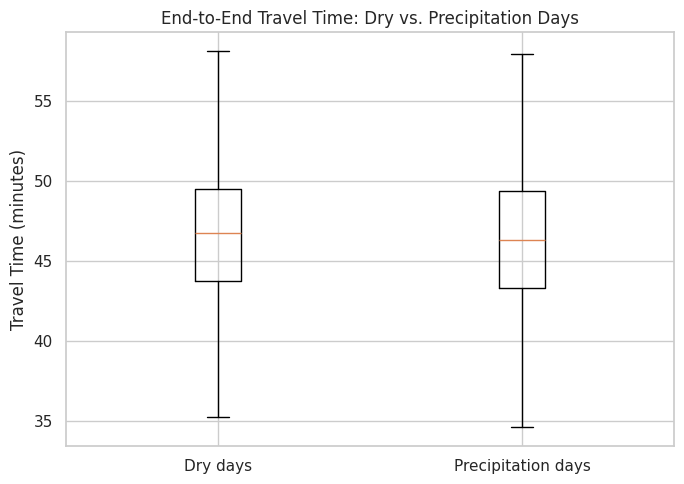

In [125]:
#Graph 6

# Map the daily precipitation to the b_line end-to-end dataset
b_line['day_type'] = np.where(b_line['HourlyPrecipitation'] > 0, 'Precipitation', 'Dry')

# Count how many days we have of each type in b_line
print("Number of unique days in each category:")
print(b_line.groupby('day_type')['date'].nunique())

# Median and mean end-to-end travel time in minutes for dry and precipitation days
print("\nMedian end-to-end travel time (minutes):")
print(b_line.groupby('day_type')['travel_time_min'].median().round(2))

print("\nMean end-to-end travel time (minutes):")
print(b_line.groupby('day_type')['travel_time_min'].mean().round(2))

# Split into dry and wet days for the box plot
dry_min = b_line[b_line['day_type'] == 'Dry']['travel_time_min']
wet_min = b_line[b_line['day_type'] == 'Precipitation']['travel_time_min']

# Chart without the outliers so the boxes are easier to compare
plt.figure(figsize=(7, 5))
plt.boxplot([dry_min, wet_min], tick_labels=['Dry days', 'Precipitation days'], showfliers=False)
plt.title('End-to-End Travel Time: Dry vs. Precipitation Days')
plt.ylabel('Travel Time (minutes)')
plt.tight_layout()
plt.show()

**Question 6 Conclusion:**  The precipitation alone does not negatively impact travel times on the Green Line B Branch. The data reveals that the median end-to-end travel time is actually slightly lower on days with precipitation (approximately 46 minutes) compared to dry days (approximately 47 minutes). Furthermore, the overall variance remains highly consistent across both weather conditions, with the middle 50% of trips falling between roughly 43.5 and 49.5 minutes, and both scenarios sharing identical minimum (35 minutes) and maximum (58 minutes) travel time boundaries. Contrary to the common assumption that rain naturally slows down transit, this distribution indicates that precipitation by itself does not cause significant delays or increase schedule unpredictability on this specific route.

## 7. Is daily precipitation amount positively correlated with average daily travel time?

*Hypothesis: On days with more precipitation trips take longer on average. The more it rains, the slower travel time gets.*


Correlation (r): 0.094


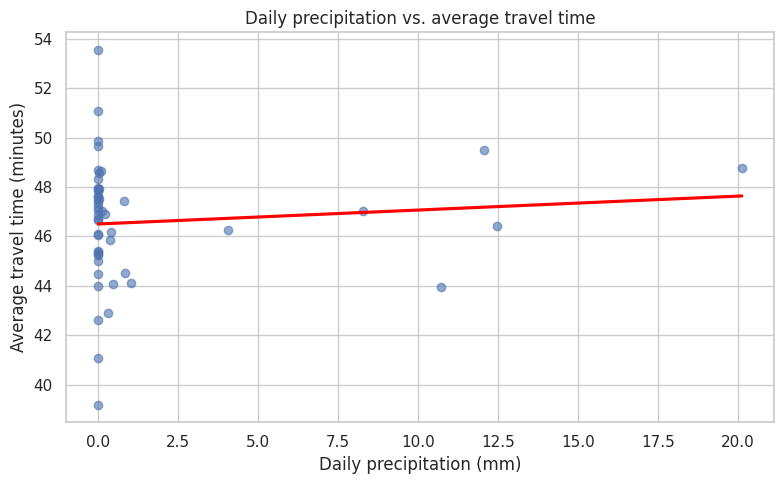

In [126]:
# Graph 7

# Get one weather reading per hour
weather = final_merged_df.drop_duplicates(["date", "hour_label"])[["date", "hour_label", "HourlyPrecipitation"]]

# Add up the hourly precipitation to get a daily total
daily_precip = weather.groupby("date")["HourlyPrecipitation"].sum()
daily_precip = daily_precip.rename("precip")

# Calculate the average end-to-end travel time for each day (b_line = Boston College to Government Center)
daily_travel = b_line.groupby("date").agg(avg_travel_min=("travel_time_min", "mean"))

# Put travel time and precipitation in one table
daily = daily_travel.join(daily_precip).reset_index()

# Correlation between precipitation and end-to-end travel time
print("Correlation (r):", round(daily["precip"].corr(daily["avg_travel_min"]), 3))

# Draw scatter plot with trend line
plt.figure(figsize=(8, 5))
sns.regplot( data=daily, x="precip", y="avg_travel_min", ci=None, scatter_kws={"alpha": 0.6}, line_kws={"color": "red"},)

# Add title, labels and show the chart
plt.xlabel("Daily precipitation (mm)")
plt.ylabel("Average travel time (minutes)")
plt.title("Daily precipitation vs. average travel time")
plt.tight_layout()
plt.show()


**Question 7 Conclusion:** The correlation between daily precipitation and average end-to-end travel time is very weak (r = 0.094). The trend line rises only slightly, by about 1 minute between dry days and the wettest day (about 20 mm). Most days in the data had little or no rain, and only a few had more than 2.5 mm. End-to-end travel times also varied a lot even on dry days, from about 39 to 54 minutes. More rain did not clearly make the trip slower.

## 8. Is the average travel time on precipitation days, compared with dry days, larger on above-ground segments than on underground segments?

*Hypothesis: Rain and snow slow down above-ground trips more than underground ones. The train tracks above-ground are exposed to the weather, while the underground tracks are protected, so the gap between dry days and wet days should be bigger above ground.*

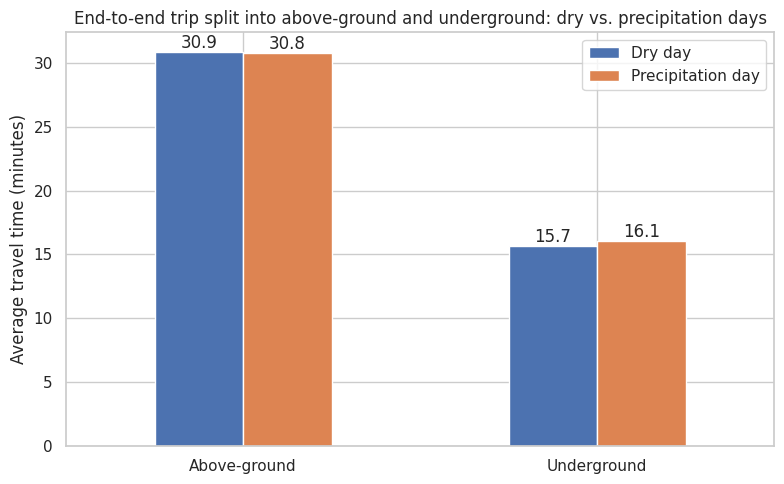

day_type      Dry day  Precipitation day  Extra minutes  Extra %
segment_type                                                    
Above-ground    30.87              30.81          -0.06    -0.20
Underground     15.68              16.07           0.38     2.45


In [127]:
# Graph 8

match_cols = ["date", "hour_label", "direction"]

# Full end-to-end trip time for each date, hour and direction (from b_line)
full = b_line[match_cols + ["travel_time_min"]].rename(columns={"travel_time_min": "full_min"})

# Above-ground section: Boston College to Kenmore
trip_sections = final_merged_df.copy()
from_stop = trip_sections["from_stop_name"]
to_stop = trip_sections["to_stop_name"]

above_ground = ["Boston College", "Kenmore"]
above = trip_sections[from_stop.isin(above_ground) & to_stop.isin(above_ground) & (from_stop != to_stop)].copy()
above["above_min"] = above["avg_travel_time_sec"] / 60

# Match each full trip with the above-ground time from the same date, hour and direction
trips = full.merge(above[match_cols + ["above_min"]], on=match_cols)

# Split the full trip: above-ground = Boston College to Kenmore, underground = the rest of the trip
trips["Above-ground"] = trips["above_min"]
trips["Underground"] = trips["full_min"] - trips["above_min"]

# Average travel time per day for each section
daily_seg = trips.groupby("date")[["Above-ground", "Underground"]].mean().reset_index()
daily_seg = daily_seg.melt(id_vars="date", var_name="segment_type", value_name="avg_travel_min")

# Mark each day as dry or a precipitation day
daily_seg = daily_seg.merge(daily_precip.reset_index(), on="date")
daily_seg["day_type"] = np.where(daily_seg["precip"] > 0, "Precipitation day", "Dry day")

# Average across days to get the bars
summary = daily_seg.pivot_table(index="segment_type",columns="day_type",values="avg_travel_min",aggfunc="mean")
summary = summary.loc[["Above-ground", "Underground"], ["Dry day", "Precipitation day"]]

# Draw the grouped bar chart
ax = summary.plot(kind="bar", figsize=(8, 5), rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f")

ax.set_xlabel("")
ax.set_ylabel("Average travel time (minutes)")
ax.set_title("End-to-end trip split into above-ground and underground: dry vs. precipitation days")
ax.legend(title="")
plt.tight_layout()
plt.show()

# How much longer trips take on precipitation days
summary["Extra minutes"] = summary["Precipitation day"] - summary["Dry day"]
summary["Extra %"] = summary["Extra minutes"] / summary["Dry day"] * 100
print(summary.round(2))

**Question 8 Conclusion:** We split the end-to-end trip (Boston College to Government Center) into its above-ground section (Boston College to Kenmore) and its underground section (Kenmore to Government Center). On precipitation days, the above-ground section barely changed (30.9 vs. 30.8 minutes, −0.2%). The underground section rose slightly, from 15.7 to 16.1 minutes (+2.5%). Precipitation did not slow down the above-ground section more than the underground section, and both changes are very small (under half a minute). Most precipitation days in the data had only light rain, so the results should be read with caution.

## 9. Is daily minimum temperature negatively correlated with the daily average travel time?

*Hypothesis: On colder days, trips take longer on average. The lower the day's minimum temperature, the slower travel time gets.*

Correlation (r): 0.458


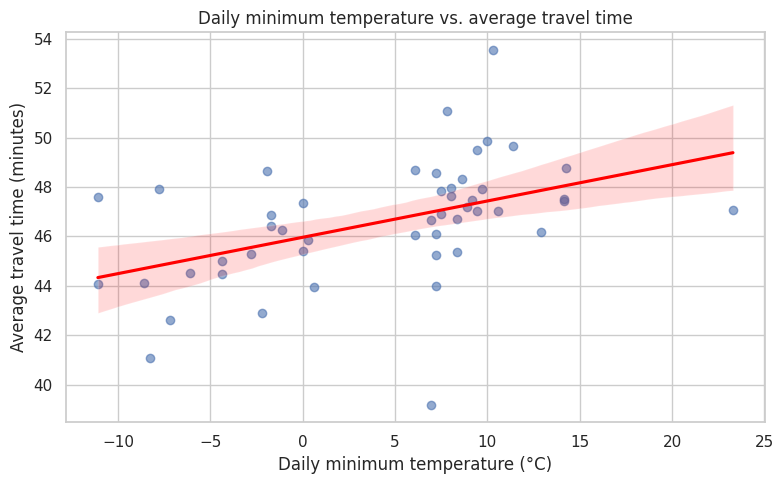

In [128]:
# Graph 9

# Get one temperature reading per hour
temps = final_merged_df.drop_duplicates(["date", "hour_label"])[["date", "hour_label", "HourlyDryBulbTemperature"]]

# Find the lowest temperature of each day
daily_min_temp = temps.groupby("date")["HourlyDryBulbTemperature"].min()
daily_min_temp = daily_min_temp.rename("min_temp")

# Put the daily end-to-end travel time (daily_travel from Question 7) and minimum temperature in one table
daily_temp = daily_travel.join(daily_min_temp).reset_index()

# Correlation between minimum temperature and end-to-end travel time
print("Correlation (r):", round(daily_temp["min_temp"].corr(daily_temp["avg_travel_min"]), 3))

# Draw the scatter plot with a trend line
plt.figure(figsize=(8, 5))
sns.regplot(data=daily_temp, x="min_temp", y="avg_travel_min", scatter_kws={"alpha": 0.6},line_kws={"color": "red"})

# Add title, labels and show the chart
plt.xlabel("Daily minimum temperature (°C)")
plt.ylabel("Average travel time (minutes)")
plt.title("Daily minimum temperature vs. average travel time")
plt.tight_layout()
plt.show()

**Question 9 Conclusion:** Instead of colder days having longer trips, we found a slight positive correlation between daily minimum temperature and average travel time (r = 0.458). The trend line rises from about 44 minutes on the coldest days (around −11°C) to about 49 minutes on the warmest (around 23°C), so warmer days had longer trips. This is likely related to the month: the warmer days are mostly in September, which Question 5 showed is busier because of the start of the fall semester. Temperature itself may not be causing the delay.

# 7. Events: Do public events increase travel time?

## 10. Is median travel time higher on event days than on non-event days?

*Hypothesis: There is significant difference in the hourly average travel time on the Green Line B Branch between event days and non-event days.*

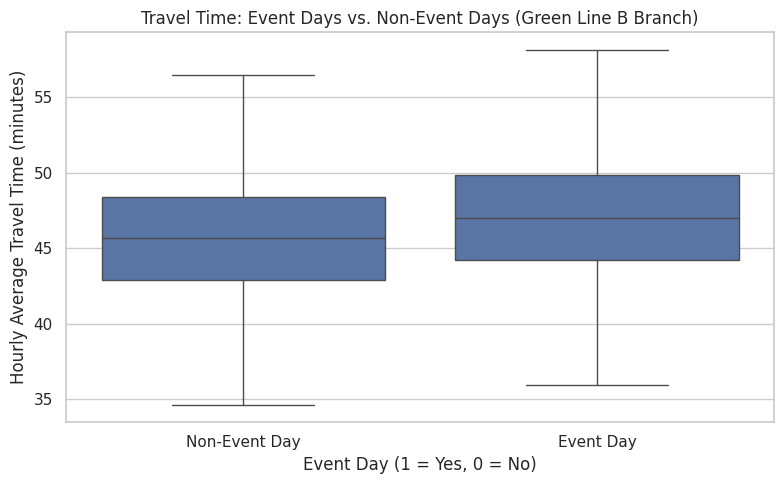

Median Travel Time (minutes):


,travel_time_min
is_event_day,
False,45.641667
True,47.031667


In [129]:
#Graph 10

# Create a binary column for event days
b_line['is_event_day'] = b_line['event_count_daily'] > 0

# Plot a box plot of travel time by event day status
plt.figure(figsize=(8, 5))
sns.boxplot(data=b_line, x='is_event_day', y='travel_time_min', showfliers=False)

# Add titles and labels
plt.title('Travel Time: Event Days vs. Non-Event Days (Green Line B Branch)')
plt.xlabel('Event Day (1 = Yes, 0 = No)')
plt.ylabel('Hourly Average Travel Time (minutes)')
plt.xticks([0, 1], ['Non-Event Day', 'Event Day'])
plt.tight_layout()
plt.show()

# Calculate and print the median travel time for event days vs. non-event days
median_travel_time_event = b_line.groupby('is_event_day')['travel_time_min'].median()
print("Median Travel Time (minutes):")
median_travel_time_event


**Question 10 Conclusion:** Median travel time was 45.64 minutes on non-event days and 47.03 minutes on event days. This indicates that public events have a negligible impact on overall end-to-end travel times on the Green Line B Branch. Which means our hypothesis stands but the margin is not that signifcant.

## 11. Are extreme end-to-end travel times, at or above the 90th percentile, more common on event days than on non-event days?

*Hypothesis: We expect the proportion of records with extreme end-to-end travel times to be higher on public event days because event-related crowds may increase passenger demand and congestion.*

90th percentile threshold (minutes): 52.47


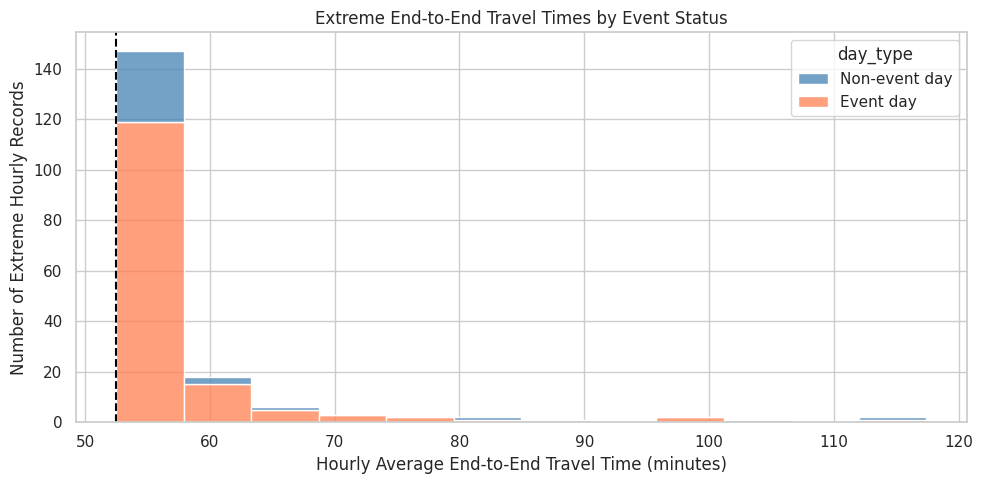

,Extreme records,Total records,Extreme rate (%)
day_type,,,
Non-event day,35,509,6.88
Event day,149,1329,11.21


In [130]:
# Graph 11

q11 = final_merged_df.copy()

# Keep only September and December 2025
q11['date'] = pd.to_datetime(q11['date'])

q11 = q11[(q11['date'].dt.year == 2025) &(q11['date'].dt.month.isin([9, 12]))].copy()

# Keep full trips between Boston College and Government Center
q11 = q11[
    (
        (q11['from_stop_name'] == 'Boston College') &
        (q11['to_stop_name'] == 'Government Center')
    ) |
    (
        (q11['from_stop_name'] == 'Government Center') &
        (q11['to_stop_name'] == 'Boston College'))].copy()

# Convert seconds to minutes
q11['travel_time_min'] = q11['avg_travel_time_sec'] / 60

# Keep valid positive travel times
q11 = q11[q11['travel_time_min'] > 0].copy()

# Label event and non-event days
q11['day_type'] = 'Non-event day'

q11.loc[q11['event_count_daily'] > 0, 'day_type'] = 'Event day'

# Calculate one threshold using all selected records
threshold = q11['travel_time_min'].quantile(0.90)

# Identify records at or above the threshold
q11['is_extreme'] = q11['travel_time_min'] >= threshold

extreme_records = q11[q11['is_extreme']].copy()

print('90th percentile threshold (minutes):',round(threshold, 2))

# Plot the frequency of extreme travel times
plt.figure(figsize=(10, 5))

sns.histplot(
    data=extreme_records,
    x='travel_time_min',
    hue='day_type',
    hue_order=['Non-event day', 'Event day'],
    bins=12,
    multiple='stack',
    palette=['steelblue', 'coral'])

# Mark the 90th percentile threshold
plt.axvline(threshold,color='black',linestyle='--')

plt.title('Extreme End-to-End Travel Times by Event Status')
plt.xlabel('Hourly Average End-to-End Travel Time (minutes)')
plt.ylabel('Number of Extreme Hourly Records')
plt.tight_layout()
plt.show()


# Count extreme records and total records in each group
summary = q11.groupby('day_type')['is_extreme'].agg(['sum', 'count'])

summary = summary.rename(columns={'sum': 'Extreme records','count': 'Total records'})

# Calculate the extreme-observation rate
summary['Extreme rate (%)'] = (summary['Extreme records'] /summary['Total records'] * 100)

summary = summary.reindex(['Non-event day', 'Event day'])

display(summary.round(2))

**Question 11 Conclusion**: Using a 90th-percentile threshold of 52.47 minutes, most extreme travel-time records were concentrated around 52–58 minutes. Extreme observations accounted for 11.21% of event-day records (149 out of 1,329), compared with 6.88% of non-event-day records (35 out of 509). This descriptively supports our hypothesis in the overall sample: unusually long travel times were proportionally more common on event days. However, this association does not prove that public events caused the longer travel times.

## 12. Which stops are hit hardest of event days?

*Hypothesis: We expect stops near Boston University and Kenmore to show larger percentage increases in travel time on event days because event crowds may increase boarding times and local traffic.*

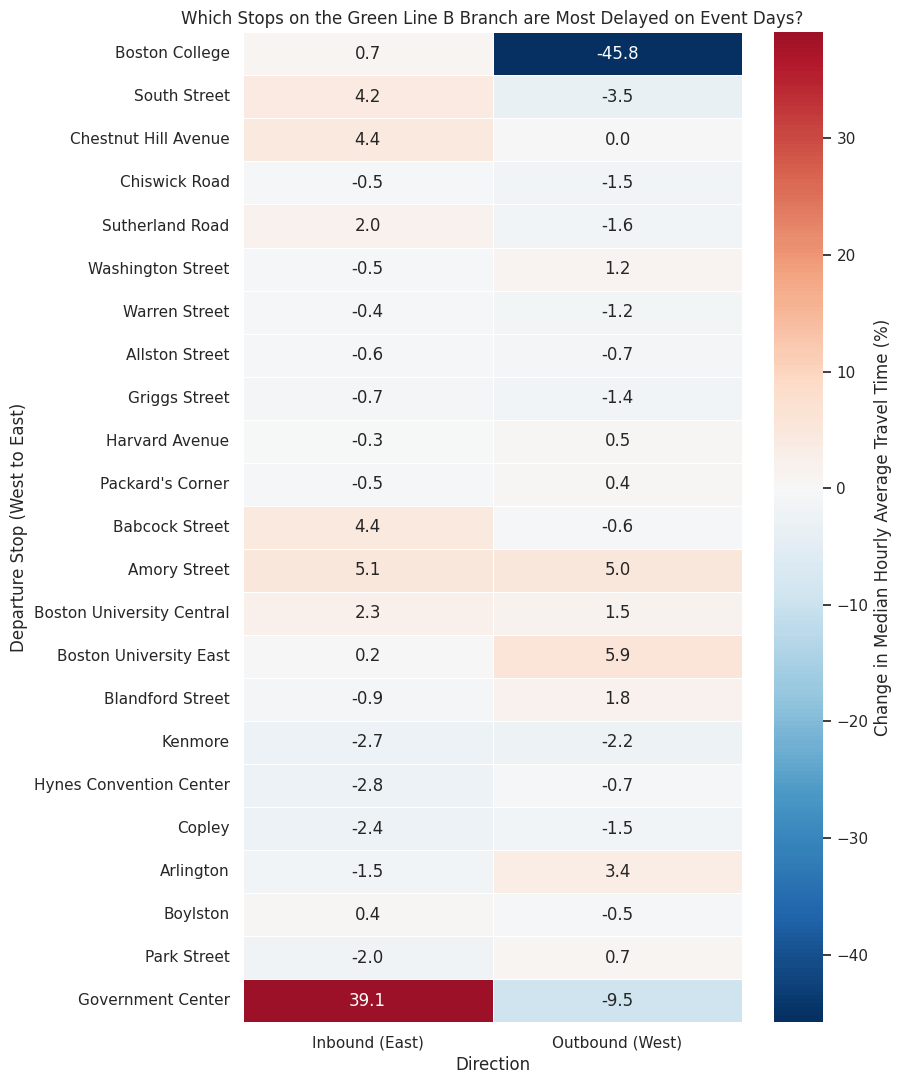

Top 10 Largest Percentage Increases on Event Days:


is_event_day                         False   True  pct_change
from_stop_name            direction                          
Government Center         East       35.73  49.70       39.07
Boston University East    West        0.52   0.55        5.89
Amory Street              East        1.74   1.82        5.05
                          West        1.27   1.33        5.04
Babcock Street            East        1.54   1.61        4.42
Chestnut Hill Avenue      East        0.51   0.53        4.37
South Street              East        1.47   1.53        4.17
Arlington                 West        1.12   1.15        3.41
Boston University Central East        0.58   0.59        2.34
Sutherland Road           East        1.40   1.43        1.98

In [131]:
# Graph 12

q12 = final_merged_df.copy()

# Convert seconds to minutes and identify event days
q12['travel_time_min'] = q12['avg_travel_time_sec'] / 60
q12['is_event_day'] = q12['event_count_daily'] > 0

# List stations from Boston College to Government Center
stops = [
    'Boston College',
    'South Street',
    'Chestnut Hill Avenue',
    'Chiswick Road',
    'Sutherland Road',
    'Washington Street',
    'Warren Street',
    'Allston Street',
    'Griggs Street',
    'Harvard Avenue',
    "Packard's Corner",
    'Babcock Street',
    'Amory Street',
    'Boston University Central',
    'Boston University East',
    'Blandford Street',
    'Kenmore',
    'Hynes Convention Center',
    'Copley',
    'Arlington',
    'Boylston',
    'Park Street',
    'Government Center'
]

# Standardize the station name
q12['from_stop_name'] = q12['from_stop_name'].astype(str).replace(
    {'Packards Corner': "Packard's Corner"})

q12['to_stop_name'] = q12['to_stop_name'].astype(str).replace(
    {'Packards Corner': "Packard's Corner"})

# Give each station a sequential number
station_number = {}

for i in range(len(stops)):
    station_number[stops[i]] = i

q12['from_number'] = q12['from_stop_name'].map(station_number)
q12['to_number'] = q12['to_stop_name'].map(station_number)

# Keep only adjacent stations
q12 = q12[(q12['from_number'] - q12['to_number']).abs() == 1].copy()

# Calculate median travel time for each group
q12_summary = q12.groupby(['from_stop_name', 'direction', 'is_event_day'],observed=True
)['travel_time_min'].median().unstack('is_event_day')

# Calculate percentage change
# False = non-event days; True = event days
q12_summary['pct_change'] = ((q12_summary[True] - q12_summary[False]) /q12_summary[False] * 100)

# Arrange the results for the heatmap
heatmap_data = q12_summary['pct_change'].unstack('direction')

# Display stations in geographical order
heatmap_data = heatmap_data.reindex(stops)

# Rename direction labels
heatmap_data = heatmap_data.rename(columns={'East': 'Inbound (East)','West': 'Outbound (West)'})

# Plot the heatmap
plt.figure(figsize=(9, 11))

ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Change in Median Hourly Average Travel Time (%)'})

# Gray cells indicate unavailable comparisons
ax.set_facecolor('lightgray')

plt.title('Which Stops on the Green Line B Branch are Most Delayed on Event Days?')
plt.xlabel('Direction')
plt.ylabel('Departure Stop (West to East)')
plt.tight_layout()
plt.show()

# Show the 10 largest percentage increases
print('Top 10 Largest Percentage Increases on Event Days:')

display(q12_summary.sort_values('pct_change', ascending=False).head(10).round(2))

**Question 12 Conclusion:** As predicted, segment travel times experienced noticeable percentage increases at university- and campus-adjacent hubs such as Boston University East (+5.9% Outbound) and Amory Street (+5.1% Inbound, +5.2% Outbound) due to boarding friction and local pedestrian crowds. However, the results also reveal two notable deviations from our initial expectations: core commercial hubs like Kenmore remained surprisingly stable or slightly faster (-2.3% to -2.8%), indicating effective mid-line transit management. Instead, the most severe disruptions were heavily concentrated at the line's geographical terminals—exemplified by a dramatic surge at Government Center (Inbound / East) (+39.1%) from post-event crowd surges, contrasted by an operational decrease at Boston College (Outbound / West) (-45.8%) driven by tactical empty-train dispatching. Overall, this demonstrates that public event disruptions on the B Branch are highly localized at terminal bottlenecks and campus segments rather than causing system-wide paralysis.

## 13. Do event days slow the line down more in December than in September?.

*Hypothesis: We expect that the increase in travel time on event days, compare with non-event days in the same month, to be larger in December than in September because winter conditions may make services less able to absorb additional passenger activity.*


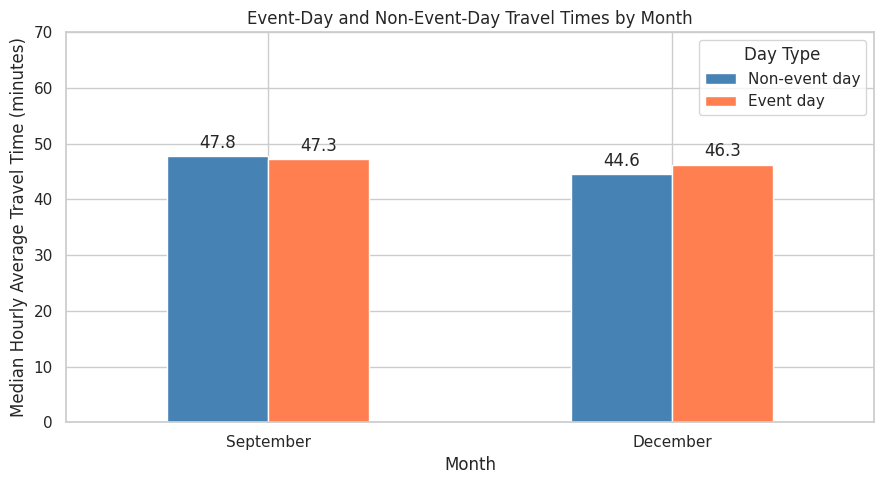

is_event_day,Non-event day,Event day,Increase (minutes)
month,,,
September,47.80,47.32,-0.48
December,44.61,46.26,1.65


December minus September event-day increase: 2.13 minutes


In [132]:
# Graph 13

import pandas as pd
import matplotlib.pyplot as plt

# Create a separate dataset for Question 13
q13 = final_merged_df.copy()

# Keep only September and December 2025
q13['date'] = pd.to_datetime(q13['date'])

q13 = q13[
    (q13['date'].dt.year == 2025) &
    (q13['date'].dt.month.isin([9, 12]))].copy()

# Keep full trips between Boston College and Government Center
q13 = q13[(
        (q13['from_stop_name'] == 'Boston College') &
        (q13['to_stop_name'] == 'Government Center')
    ) |
    (
        (q13['from_stop_name'] == 'Government Center') &
        (q13['to_stop_name'] == 'Boston College')
    )
].copy()

# Convert seconds to minutes
q13['travel_time_min'] = q13['avg_travel_time_sec'] / 60

# Keep valid positive travel times
q13 = q13[q13['travel_time_min'] > 0].copy()

# Identify event days
q13['is_event_day'] = q13['event_count_daily'] > 0

# Create month labels
q13['month'] = q13['date'].dt.month.map({9: 'September',12: 'December'})

# Calculate median travel time for each group
q13_summary = q13.groupby(['month', 'is_event_day'])['travel_time_min'].median().unstack('is_event_day')

# Rename the columns
q13_summary = q13_summary.rename(columns={False: 'Non-event day',True: 'Event day'})

# Arrange the months in order
q13_summary = q13_summary.reindex(['September','December'])

# Plot the grouped bar chart
ax = q13_summary.plot(kind='bar',figsize=(9, 5),color=['steelblue', 'coral'])

# Add values above the bars
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f', padding=3)

plt.title('Event-Day and Non-Event-Day Travel Times by Month')
plt.xlabel('Month')
plt.ylabel('Median Hourly Average Travel Time (minutes)')
plt.xticks(rotation=0)
plt.ylim(0, 70)
plt.legend(title='Day Type', loc='upper right')
plt.tight_layout()
plt.show()

# Calculate the event-day increase within each month
q13_summary['Increase (minutes)'] = (
    q13_summary['Event day'] -
    q13_summary['Non-event day'])

# Display the comparison table
display(q13_summary.round(2))

# Compare the increases between December and September
difference = (q13_summary.loc['December', 'Increase (minutes)'] -q13_summary.loc['September', 'Increase (minutes)'])

print('December minus September event-day increase:',round(difference, 2),'minutes')

**Question 13 Conclusion:** Using the median of hourly average travel times, September event days recorded 47.32 minutes, compared with 47.80 minutes on non-event days, a decrease of 0.48 minutes. In December, event days recorded 46.26 minutes, compared with 44.61 minutes on non-event days, an increase of 1.65 minutes. Therefore, the event-day versus non-event-day gap was 2.13 minutes larger in December. This suggests a stronger event-related slowdown in December, although this comparison alone cannot confirm that winter conditions caused the difference.


# 8. Rider impact: Does the combination of events and weather hurt The MBTA Green Line B-Branch reliability?

## 14. Is the delay on days with both precipitation and an event greater than the delay on weather-only days plus the delay on event-only days?

*Hypothesis: There is significant difference in the average travel time on the Green Line B Branch across the four conditions "Neither", "Weather Only", "Event Only", and both.*

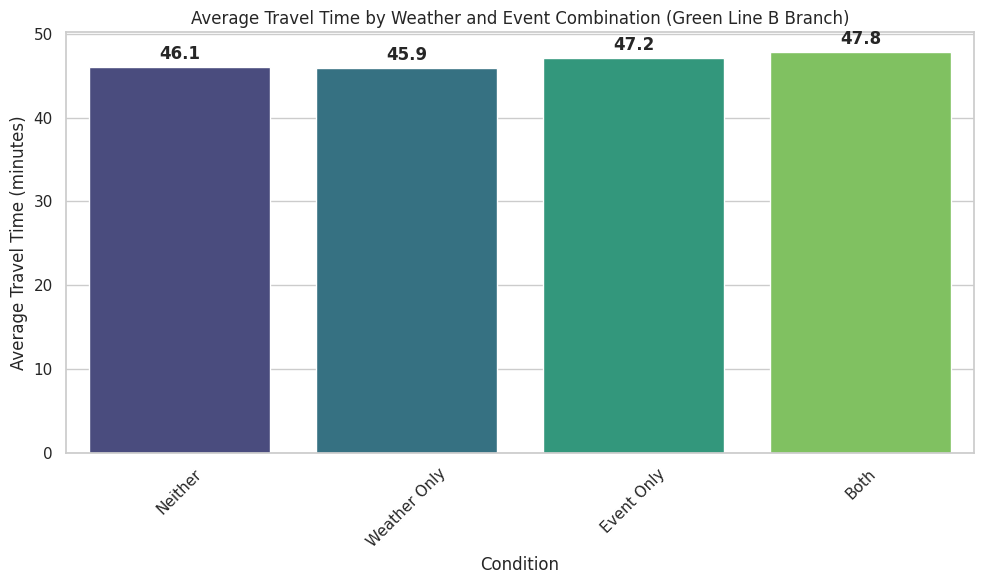

Average Travel Time (minutes) by Condition:


,weather_event_combo,travel_time_min
2,Neither,46.057500
3,Weather Only,45.928203
1,Event Only,47.162585
0,Both,47.799269


In [133]:
#Graph 14

# Create a categorical variable for the combination of weather and events
b_line['weather_event_combo'] = 'Neither'
b_line.loc[(b_line['HourlyPrecipitation'] > 0) & (b_line['event_count_daily'] == 0), 'weather_event_combo'] = 'Weather Only'
b_line.loc[(b_line['HourlyPrecipitation'] == 0) & (b_line['event_count_daily'] > 0), 'weather_event_combo'] = 'Event Only'
b_line.loc[(b_line['HourlyPrecipitation'] > 0) & (b_line['event_count_daily'] > 0), 'weather_event_combo'] = 'Both'

# Calculate the average travel time for each category
avg_travel_time_by_combo = b_line.groupby('weather_event_combo')['travel_time_min'].mean().reset_index()

# Define the order for the categories
category_order = ['Neither', 'Weather Only', 'Event Only', 'Both']
avg_travel_time_by_combo['weather_event_combo'] = pd.Categorical(avg_travel_time_by_combo['weather_event_combo'], categories=category_order, ordered=True)
avg_travel_time_by_combo = avg_travel_time_by_combo.sort_values('weather_event_combo')

# Plot the grouped bar chart
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=avg_travel_time_by_combo, x='weather_event_combo', y='travel_time_min', palette='viridis', hue='weather_event_combo', legend=False)

# Add values on top of each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f', padding=3, fontweight='bold')

# Add titles and labels
plt.title('Average Travel Time by Weather and Event Combination (Green Line B Branch)')
plt.xlabel('Condition')
plt.ylabel('Average Travel Time (minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Average Travel Time (minutes) by Condition:")
display(avg_travel_time_by_combo)

**Question 14 Conclusion:** Compared with days with neither rain nor events (46.1 min), rain alone made almost no difference (45.9 min). Events alone added about 1.1 minutes (47.2 min), and days with both added about 1.7 minutes (47.8 min). The combined delay is larger than the two separate delays added together (about 1.0 min). This suggests weather and events have more effect together than alone, although the differences are small and we did not run a significance test.


## 15. On days with both precipitation and an event, do above-ground stretches slow down more than underground stretches?

*Hypothesis: External conditions such as rain and special events have a differential impact on average travel times between the above-ground and underground segments of the Green Line. Any variations in travel time across these conditions are due to random chance.*

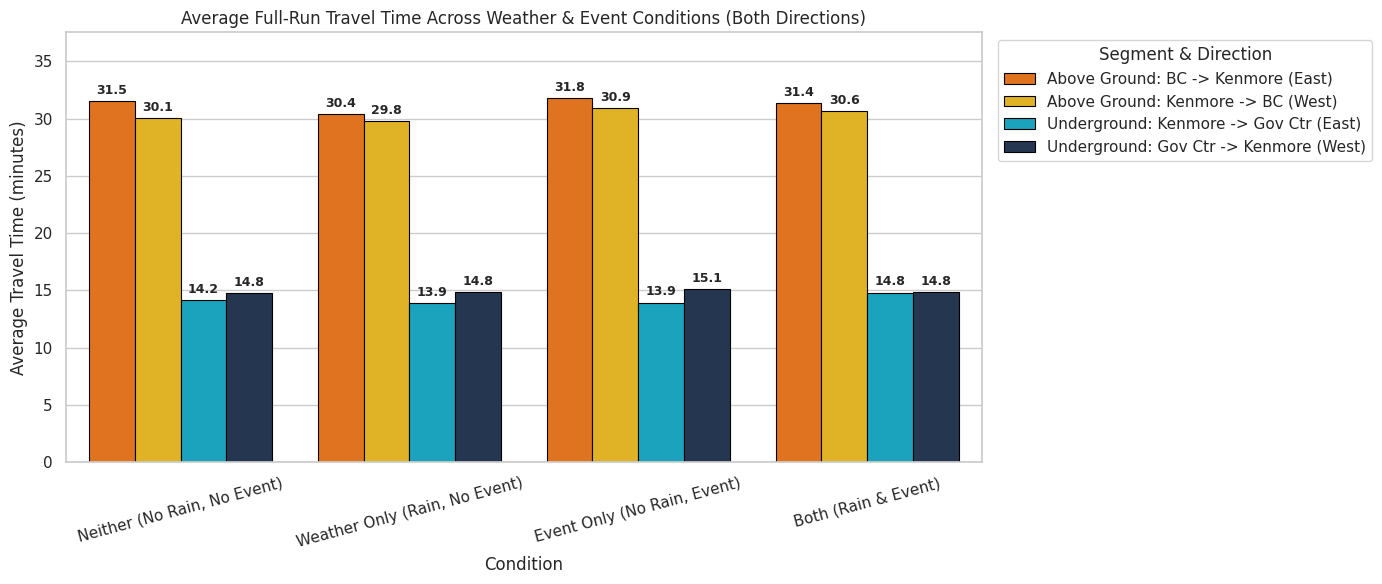

Average Full-Run Travel Time (minutes) by Condition, Segment, and Direction:


segment_type,Above Ground: BC -> Kenmore (East),Above Ground: Kenmore -> BC (West),Underground: Kenmore -> Gov Ctr (East),Underground: Gov Ctr -> Kenmore (West)
condition,,,,
"Neither (No Rain, No Event)",31.54,30.07,14.17,14.78
"Weather Only (Rain, No Event)",30.40,29.81,13.93,14.85
"Event Only (No Rain, Event)",31.81,30.89,13.95,15.09
Both (Rain & Event),31.37,30.63,14.81,14.84


In [134]:
#Graph 15

# Calculate full-run average travel times for Above-ground (BC <-> Kenmore) and Underground (Kenmore <-> Gov Center) for both directions
df_all_stops = final_merged_df.copy()
df_all_stops['travel_time_min'] = df_all_stops['avg_travel_time_sec'] / 60

# Create the 4 weather and event conditions
df_all_stops['condition'] = 'Neither (No Rain, No Event)'
df_all_stops.loc[(df_all_stops['HourlyPrecipitation'] > 0) & (df_all_stops['event_count_daily'] == 0), 'condition'] = 'Weather Only (Rain, No Event)'
df_all_stops.loc[(df_all_stops['HourlyPrecipitation'] == 0) & (df_all_stops['event_count_daily'] > 0), 'condition'] = 'Event Only (No Rain, Event)'
df_all_stops.loc[(df_all_stops['HourlyPrecipitation'] > 0) & (df_all_stops['event_count_daily'] > 0), 'condition'] = 'Both (Rain & Event)'

# Identify full-run paths
cond_above_east = (df_all_stops['from_stop_name'] == 'Boston College') & (df_all_stops['to_stop_name'] == 'Kenmore')
cond_above_west = (df_all_stops['from_stop_name'] == 'Kenmore') & (df_all_stops['to_stop_name'] == 'Boston College')
cond_under_east = (df_all_stops['from_stop_name'] == 'Kenmore') & (df_all_stops['to_stop_name'] == 'Government Center')
cond_under_west = (df_all_stops['from_stop_name'] == 'Government Center') & (df_all_stops['to_stop_name'] == 'Kenmore')

all_mask = cond_above_east | cond_above_west | cond_under_east | cond_under_west
df_segments = df_all_stops[all_mask].copy()

df_segments['segment_type'] = np.select(
    [
        cond_above_east[all_mask],
        cond_above_west[all_mask],
        cond_under_east[all_mask],
        cond_under_west[all_mask]
    ],
    [
        'Above Ground: BC -> Kenmore (East)',
        'Above Ground: Kenmore -> BC (West)',
        'Underground: Kenmore -> Gov Ctr (East)',
        'Underground: Gov Ctr -> Kenmore (West)'
    ],
    default='Other'
)

condition_order = [
    'Neither (No Rain, No Event)',
    'Weather Only (Rain, No Event)',
    'Event Only (No Rain, Event)',
    'Both (Rain & Event)'
]

# Calculate average travel time grouped by condition and directional full-run segments
plot_data = (
    df_segments.groupby(['condition', 'segment_type'])['travel_time_min']
    .mean()
    .reset_index()
)
plot_data['condition'] = pd.Categorical(plot_data['condition'], categories=condition_order, ordered=True)
plot_data = plot_data.sort_values(['condition', 'segment_type'])

# Warm colors (Orange/Amber) for Above Ground full runs, Cool colors (Blues) for Underground full runs
colors = ['#FF6F00', '#FFC107', '#00B4D8', '#1D3557']
segment_order = [
    'Above Ground: BC -> Kenmore (East)',
    'Above Ground: Kenmore -> BC (West)',
    'Underground: Kenmore -> Gov Ctr (East)',
    'Underground: Gov Ctr -> Kenmore (West)'
]

# Plot grouped bar chart
plt.figure(figsize=(14, 6))
ax = sns.barplot(
    data=plot_data,
    x='condition',
    y='travel_time_min',
    hue='segment_type',
    hue_order=segment_order,
    palette=colors,
    edgecolor='black',
    linewidth=0.8
)

# Put values on top of each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=9, fontweight='bold')

plt.title('Average Full-Run Travel Time Across Weather & Event Conditions (Both Directions)')
plt.xlabel('Condition')
plt.ylabel('Average Travel Time (minutes)')
plt.ylim(0, plot_data['travel_time_min'].max() * 1.18)
plt.legend(title='Segment & Direction', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("Average Full-Run Travel Time (minutes) by Condition, Segment, and Direction:")
display(plot_data.pivot(index='condition', columns='segment_type', values='travel_time_min')[segment_order].round(2))

**Question 15 Conclusion:** The above-ground section (Boston College–Kenmore) takes about twice as long as the underground section (Kenmore–Government Center), about 30–32 vs. 14–15 minutes, in every condition. Within each section, travel times changed by less than 1.5 minutes across the four weather and event conditions. Neither section slowed down noticeably more on days with both rain and an event. The gap between the sections comes from the above-ground section being longer, not from weather or events.

# 9. Conclusion & Recommendations

**Final Conclusion：**

Based on the analysis of the Green Line B Branch, the primary source of schedule unpredictability is the above-ground segment of the line. Even on perfectly normal days without precipitation or special events, the above-ground stops between Boston College and Kenmore demonstrate nearly triple the travel time variance compared to the underground segments.   

While commuter volume during rush hour does increase the overall length of a trip, it actually makes the travel time more consistent. Peak hours add approximately 1.5 minutes to the median end-to-end travel time, but they result in a tighter standard deviation of 5.6 minutes, compared to a 6.6-minute standard deviation during off-peak hours. This indicates that off-peak travel is noticeably less predictable.   

Congestion impacts also vary significantly by direction and season. During the morning peak, inbound trips toward Government Center are slower than outbound trips, whereas evening peak travel times are similar in both directions but run 4 to 6 minutes slower than morning commutes. Furthermore, baseline travel is substantially slower during the September back-to-school rush, which sees a median travel time of 47.8 Mins per segment compared to 43.1 mins in December.

**Recommendations**

For the MBTA:

Implement Transit Signal Priority (TSP): Because the above-ground segments are the primary bottleneck for reliability, the MBTA should work with the City of Boston to implement or optimize signal priority at major Commonwealth Avenue intersections to decouple train pacing from street-level car traffic.   

Targeted September Capacity Increases: Since baseline travel is significantly slower in September than in December, the MBTA should deploy high-capacity trains or increase frequency specifically during the fall university move-in period to absorb the surge in ridership.   

Dynamic Event-Weather Scheduling: Knowing that the combination of adverse weather and public events creates peak delays, the MBTA should utilize predictive weather forecasting paired with the city's event permit database to proactively deploy standby trains and increase platform staffing on high-risk days.

For Riders:

Off-Peak Variability: Commuters navigating the Commonwealth Avenue corridor—including the student body at Questrom and the wider Boston University community—should pad their schedules more heavily during off-peak hours, as the data shows these times are highly susceptible to unpredictable delays.   

Plan for Fall Commute Friction: Riders should permanently adjust their baseline travel expectations for September, budgeting at least 5 to 10 extra minutes for end-to-end trips compared to their winter routines.   

# 10. Challenges

Our three datasets came from different sources and were recorded at different time levels, so most of our challenges came up while cleaning and merging them, which was mostly completed in the first phase of the Team Assignment.

The MBTA travel-time data set had every Green Line branch, so we filtered `route_id` to `'Green-B'` only because we wanted to focus on only the B Branch of the Green Line. That left 1,774,241 rows for September 2025 and 1,117,499 for December 2025. Each row was a single trip between two stops, which was too detailed to merge with the other data. We grouped travel times by date, hour, direction and stop pair, and kept the average travel time and the trip count. Our final merged dataset had 539,798 rows.

The weather data was messy because some columns had mixed data types, trace precipitation was recorded as "T", and some values had letters or asterisks in them. Many values were missing, including 6,709 hourly precipitation values. We filled snow depth within the same day using the nearby readings, and we filled the rest with 0. Some hours had more than one reading, so we averaged them to get one row per date and hour.

The datasets were also at different time intervals, which was another challenge. Travel times and weather were hourly, but events were only recorded by day. We gave the travel-time and weather tables the same AM/PM hour label and merged them on date and hour. Then we counted events per day and joined them on date. The event file covered more than 2025 and had many columns with missing values. We kept only 2025 events and dropped the incomplete columns. The merged data also included January 1, 2026, so we filtered it to keep only September 2025 and December 2025.

For our hypothesis driven questions, we kept only completed Boston College to Government Center trips (1,873 rows) so every row covers the same distance, rather than the ones that only covered part of the trip. One station name was spelled two ways ("Packards Corner" and "Packard's Corner"), so we standardized it to clean the data. To help make the data visualizations more easy to understand, we hid outliers in the box plots and cut the histogram at the 99th percentile, but our calculations still reflected the whole dataset.

Finally, some of our comparison groups were small or uneven. We had only 9 baseline days with no rain and no events (4 in September and 5 in December). We had 25 precipitation days and 36 dry days, and event days had significantly more records than non-event days (1,329 vs. 509). Please note that many of these conclusions should be read with caution due to these inconcistencies between the merged data sets. Weather, departure hour and event size can also overlap, so we describe our findings as associations.

# 11. References
1. GeeksforGeeks. 2016. “Graph Plotting in Python | Set 1.” GeeksforGeeks. December 12, 2016. https://www.geeksforgeeks.org/python/graph-plotting-in-python-set-1/.
2. GeeksforGeeks. 2024. “Python | Pandas Merging, Joining and Concatenating.” GeeksforGeeks. June 13, 2024. https://www.geeksforgeeks.org/pandas/python-pandas-merging-joining-and-concatenating/.
3. Truitt, Brandon. 2026. “Boston Commuters Facing Another Week of MBTA Green Line Closures.” CBS News. CBS Boston. September 28, 2026. https://www.cbsnews.com/boston/news/green-line-mbta-closure-repair/.
4. Katcher, Will. 2026. “Major Portions of the MBTA’s Green and Orange Lines Face Shutdowns in September.” Masslive. September 6, 2026. https://www.masslive.com/boston/2026/09/major-portions-of-the-mbtas-green-and-orange-lines-face-shutdowns-in-september.html.
5. Katcher, Will. 2026. “Extreme Weather Will Threaten the MBTA as Climate Warms. Here’s the Agency’s New Plan to Fight Back.” Masslive. April 30, 2026. https://www.masslive.com/boston/2026/05/extreme-weather-will-threaten-the-mbta-as-climate-warms-heres-the-agencys-new-plan-to-fight-back.html.
6. Massachusetts Bay Transportation Authority. 2018. “Beginner’s Guide to the Subway | MBTA User Guides | MBTA.” Mbta.Com. 2018. https://www.mbta.com/guides/subway-guide.
7. BA780 GitHub Library: https://github.com/soltaniehha/Intro-to-Data-Analytics


# 12. Generative AI statement

**Generative AI Disclosure**

We used Claude (Anthropic), Google Gemini and ChatGPT/GPT (OpenAI) throughout the development of this project. Generative AI assisted with all sections of the written report and supported the analytical workflow, including research planning, data preparation, Python programming, descriptive analysis, visualization, and interpretation. All work and insights were reviewed by the team to ensure accuracy.

**1. Research Planning and Report Organization**

AI helped develop and refine the business problem, research objectives, research questions, and hypotheses. It supported the organization of the notebook into a logical progression from baseline performance to weather effects, public events, and combined disruptions. It also helped connect the analyses to practical implications for riders and transit operations.

**2. Data Understanding, Cleaning, and Preparation**

AI helped explain dataset fields and suggest approaches to selecting relevant records, converting dates and numeric variables, handling missing or inconsistent values, standardizing station names, and preparing data for analysis. Assistance also covered filtering the relevant year and months, aggregating travel-time observations, and understanding how transit, weather, and event information could be combined using the available date and hour fields.

**3. Python Code Generation and Debugging**

Claude and GPT supported the generation, revision, and explanation of Python code using pandas, NumPy, Matplotlib, and Seaborn. Assistance included filtering, grouping, merging, unit conversion, summary calculations, and plotting. The tools also helped troubleshoot errors involving undefined variables, data types, column names, and calculation logic. Explanations and simpler code alternatives were requested to support our understanding of the implementation.

**4. Analysis and Interpretation**

AI helped formulate and explain descriptive comparisons involving means, medians, standard deviations, percentage changes, percentile thresholds, and occurrence rates. It supported comparisons across peak and off-peak periods, directions, months, weather conditions, event status, and above-ground versus underground sections. AI also helped explain numerical results, assess whether patterns were consistent with the proposed hypotheses, and identify limitations affecting interpretation.

**5. Data Visualization**

AI helped select and implement charts appropriate to the research questions, including line charts, box plots, histograms, scatter plots with trend lines, grouped bar charts, and heatmaps. It also assisted with chart titles, axis labels, legends, category ordering, annotations, and readability. The figures were produced through Python code using the project datasets.

**6. Writing, Editing, and Language Support**

AI assisted with drafting, revising, and organizing written material throughout the report. This included introductory and background text, the problem statement, methodological explanations, analysis summaries, figure interpretations, conclusions, recommendations, and discussion of challenges and limitations. It also helped improve English grammar, clarity, consistency, this disclosure was also drafted and revised with AI assistance.

**7. Data Evidence and Team Responsibility**

Our team was responsible for selecting and incorporating AI suggestions and for the accuracy of the submitted code, figures, calculations, written claims, and references.